# Results
Run `bash scripts/finalize.sh` (or the individual scripts) first. Cells skip gracefully if a file is missing.

In [1]:
import pathlib, re, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
ROOT = pathlib.Path('..') if pathlib.Path('../benchmarks/results').exists() else pathlib.Path('.')
R = ROOT / 'benchmarks' / 'results'; L = ROOT / 'logs'
sys.path.insert(0, str(ROOT / 'scripts'))
from make_results_tables import LABELS, GROUPS, pretty
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## 1. Baseline iteration counts (Poisson)

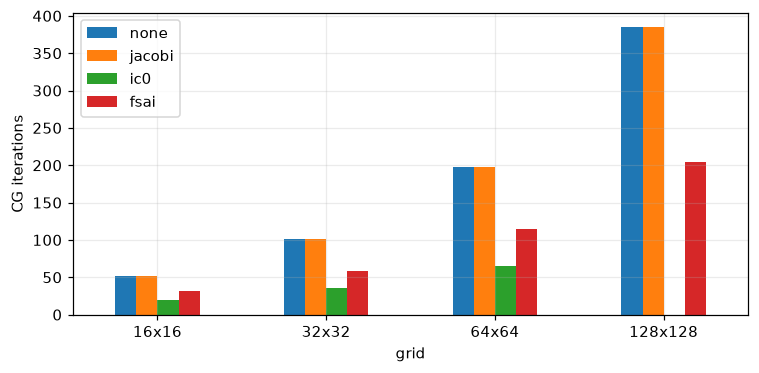

In [2]:
b = pd.read_csv(R/'day1_baselines.csv')
cols = [c for c in ['none','jacobi','ic0','fsai'] if c in b]
b.set_index('grid')[cols].plot.bar(figsize=(7,3.5), rot=0); plt.ylabel('CG iterations'); plt.tight_layout(); plt.show()

## 2. Training curves (validation CG iterations on Poisson 32², from `logs/`)
This matrix is in-distribution: it shows the model learns FSAI quality, not generalization.

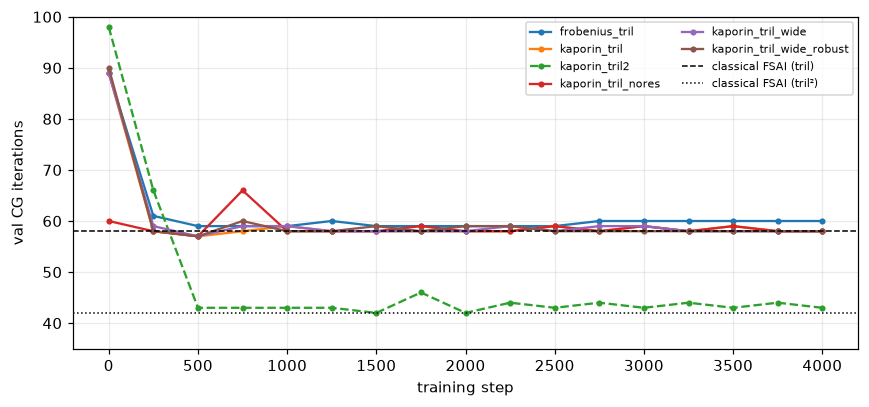

In [3]:
pat = re.compile(r"step\s+(\d+)\s+train\s+\S+\s+\S+\s+val CG iters \(32\^2\)\s+(\d+)")
fig, ax = plt.subplots(figsize=(8, 3.8)); found = False; text = ''
for f in sorted(L.glob('*.log')) if L.exists() else []:
    txt = f.read_text(); text += txt
    pts = [(int(m.group(1)), int(m.group(2))) for m in map(pat.search, txt.splitlines()) if m]
    if pts:
        found = True; ax.plot(*zip(*pts), marker='.', label=f.stem, ls='--' if 'tril2' in f.stem else '-')
for key, lab in (('tril', 'classical FSAI (tril)'), ('tril2', 'classical FSAI (tril²)')):
    t = re.search(rf"FSAI\({key}\)=(\d+)", text)
    if t: ax.axhline(int(t.group(1)), color='k', ls=':' if key == 'tril2' else '--', lw=1, label=lab)
ax.set_xlabel('training step'); ax.set_ylabel('val CG iterations'); ax.set_ylim(35, 100)
if found: ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 3. GNN vs baselines (final weights)

In [4]:
f = R/'eval_all.csv'
e = pd.read_csv(f) if f.exists() else None
if e is not None:
    if 'converged' not in e: e['converged'] = True
    it = e.pivot_table(index='matrix', columns='method', values='iters', aggfunc='first')
    cv = e.pivot_table(index='matrix', columns='method', values='converged', aggfunc='first')
    order = [m for g in GROUPS for m in g[1] if m in it.index]
    meths = [m for m in ['none','jacobi','ic0','pyamg_amg','fsai_tril','fsai_tril2'] if m in it.columns] + sorted(m for m in it.columns if m.startswith('gnn_'))
    t = it.loc[order, meths].rename(index=LABELS, columns=pretty)
    display(t.round(0).astype('Int64'))
else:
    print('eval_all.csv not found - run scripts/evaluate_checkpoint.py')

method,none,jacobi,IC(0),AMG (pyamg),FSAI (tril),FSAI (tril²),GNN Frobenius tril,GNN Kaporin tril²,GNN Kaporin tril,GNN Kaporin tril (wide),"GNN Kaporin tril (wide, robust)"
matrix,,,,,,,,,,,
Poisson 16²,52,52,20,6,30,23,31,23,30,30,30
Poisson 32²,101,101,34,7,58,41,60,43,58,58,58
Poisson 64²,199,199,65,8,113,81,110,83,113,113,113
Poisson 128² (unseen size),379,379,<NA>,8,201,153,206,158,201,202,202
Anisotropic 64² (ay=0.01),366,366,32,31,195,136,204,166,197,198,196
Random 2D family #0,150,150,50,7,81,61,82,63,81,81,81
Random 2D family #1,210,209,62,8,111,79,114,88,111,111,111
Random 2D family #2,198,198,65,8,113,80,116,83,113,114,113
3D Poisson 16³,64,64,23,6,36,27,38,32,37,36,36


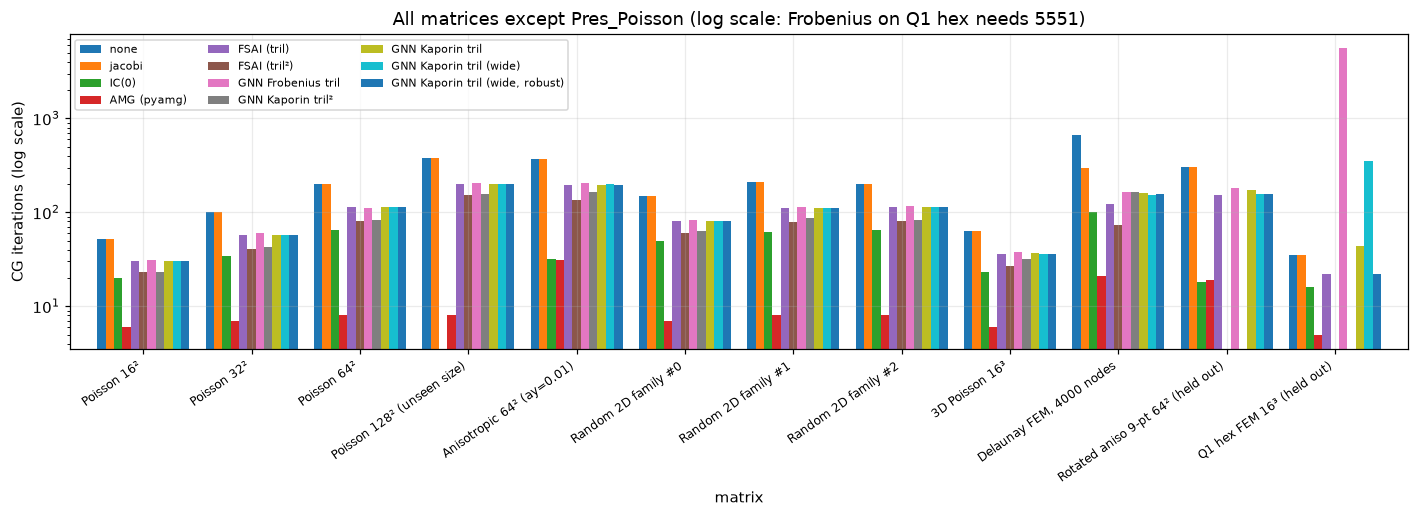

In [5]:
if e is not None:
    sub = [m for m in order if m != 'suitesparse']
    t2 = it.loc[sub, meths].rename(index=LABELS, columns=pretty)
    t2.plot.bar(figsize=(13,4.8), width=.85, logy=True); plt.ylabel('CG iterations (log scale)'); plt.xticks(rotation=35, ha='right', fontsize=8)
    plt.legend(fontsize=7, ncol=3); plt.title('All matrices except Pres_Poisson (log scale: Frobenius on Q1 hex needs 5551)'); plt.tight_layout(); plt.show()

## 4. How far is each GNN from classical FSAI? (% more iterations; ✗ = no convergence)

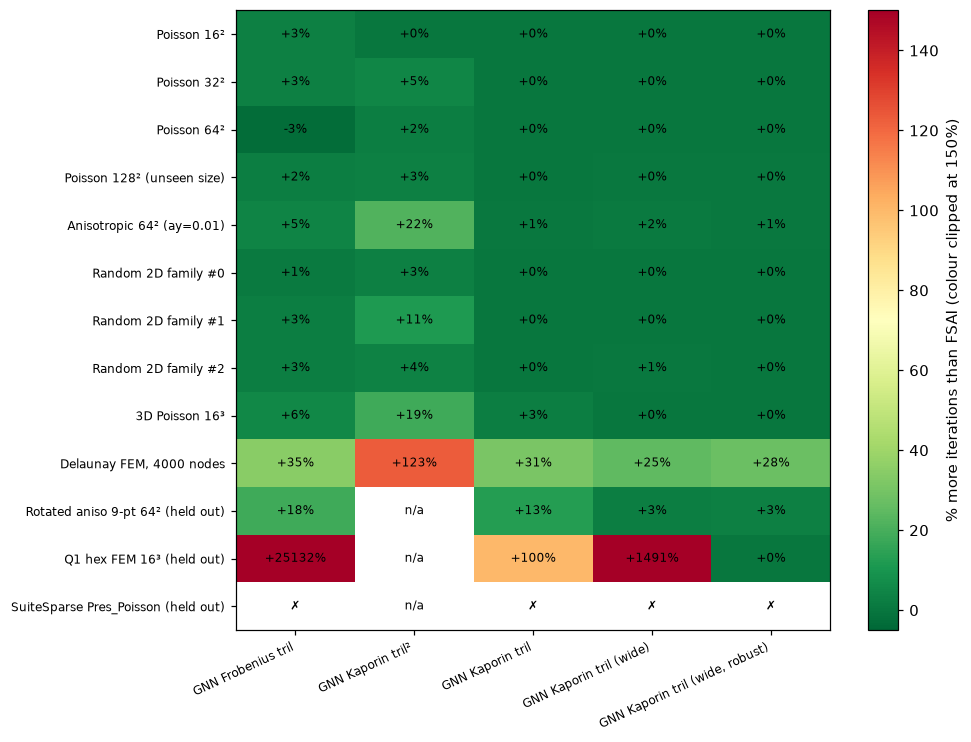

In [6]:
if e is not None:
    gn = [m for m in meths if m.startswith('gnn_')]
    gap = pd.DataFrame(index=order, columns=gn, dtype=float); note = pd.DataFrame('', index=order, columns=gn)
    for mat in order:
        for m in gn:
            ref = 'fsai_tril2' if 'tril2' in m else 'fsai_tril'
            v, fv = it.at[mat, m], it.at[mat, ref] if ref in it.columns else np.nan
            if pd.isna(v) or pd.isna(fv): note.at[mat, m] = 'n/a'; continue
            if not bool(cv.at[mat, m]): note.at[mat, m] = '✗'; continue
            gap.at[mat, m] = (v / fv - 1) * 100
    fig, ax = plt.subplots(figsize=(1.6 + 1.5*len(gn), 0.45*len(order) + 1))
    im = ax.imshow(np.clip(gap.values.astype(float), -5, 150), cmap='RdYlGn_r', aspect='auto', vmin=-5, vmax=150)
    for i, mat in enumerate(order):
        for j, m in enumerate(gn):
            txt = note.iat[i, j] or f"{gap.iat[i, j]:+.0f}%"
            ax.text(j, i, txt, ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(gn))); ax.set_xticklabels([pretty(m) for m in gn], rotation=25, ha='right', fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([LABELS.get(m, m) for m in order], fontsize=8); ax.grid(False)
    plt.colorbar(im, label='% more iterations than FSAI (colour clipped at 150%)'); plt.tight_layout(); plt.show()

## 5. Held-out matrices: iterations relative to no preconditioner (below 1 = helps, above 1 = hurts)

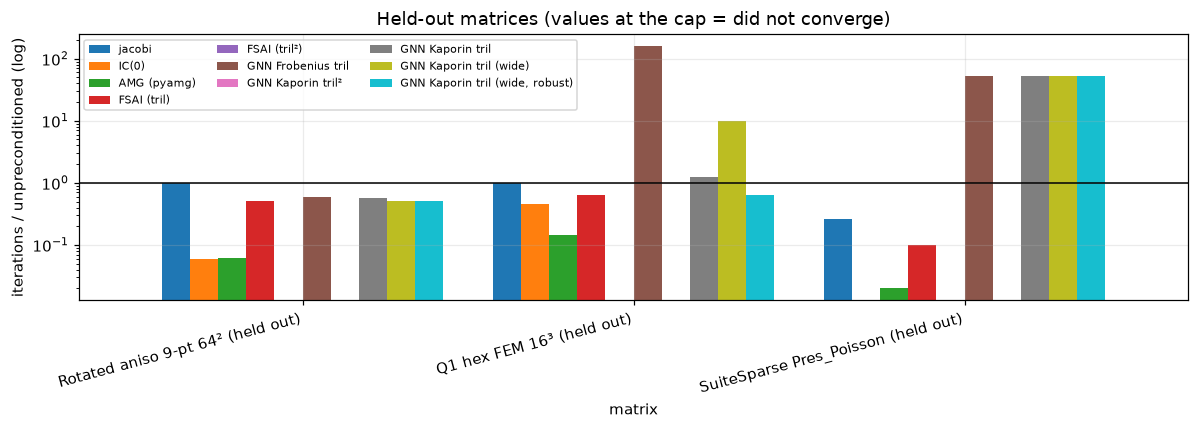

In [7]:
if e is not None:
    held = [m for m in ['heldout_rotaniso9_64','heldout_q1hex_16','suitesparse'] if m in it.index]
    show = [m for m in meths if m != 'none']
    rel = (it.loc[held, show].div(it.loc[held, 'none'], axis=0)).rename(index=LABELS, columns=pretty)
    ax = rel.plot.bar(figsize=(11,4), logy=True, width=.85); ax.axhline(1, color='k', lw=1)
    ax.set_ylabel('iterations / unpreconditioned (log)'); plt.xticks(rotation=15, ha='right'); plt.legend(fontsize=7, ncol=3)
    plt.title('Held-out matrices (values at the cap = did not converge)'); plt.tight_layout(); plt.show()

## 6. Residual history, Poisson 64²

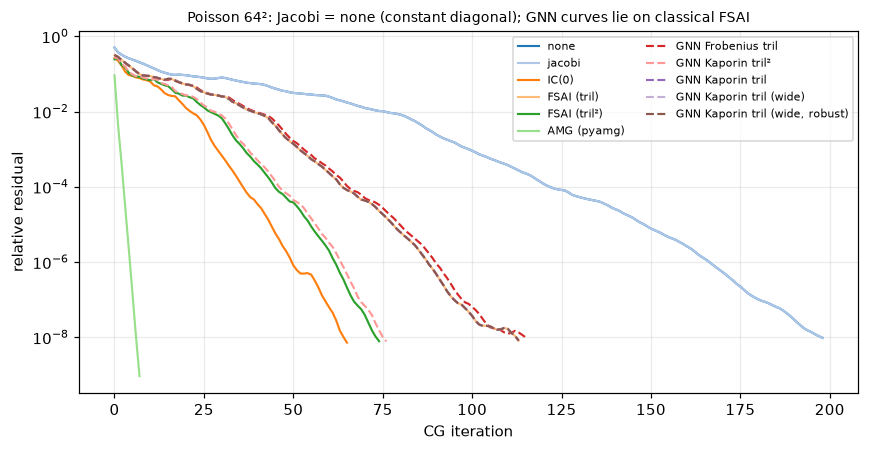

In [8]:
f = R/'eval_curves.npz'
if f.exists():
    c = np.load(f); cmap = plt.get_cmap('tab20')
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, k in enumerate(c.files):
        ax.semilogy(c[k], label=pretty(k), color=cmap(i % 20), ls='--' if k.startswith('gnn_') else '-', lw=1.4)
    ax.set_xlabel('CG iteration'); ax.set_ylabel('relative residual'); ax.legend(fontsize=7, ncol=2)
    ax.set_title('Poisson 64²: Jacobi = none (constant diagonal); GNN curves lie on classical FSAI', fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print('eval_curves.npz not found')

## 7. Does the loss predict iterations? (FSAI-family stand-in study, 32 matrices x 6 preconditioners)

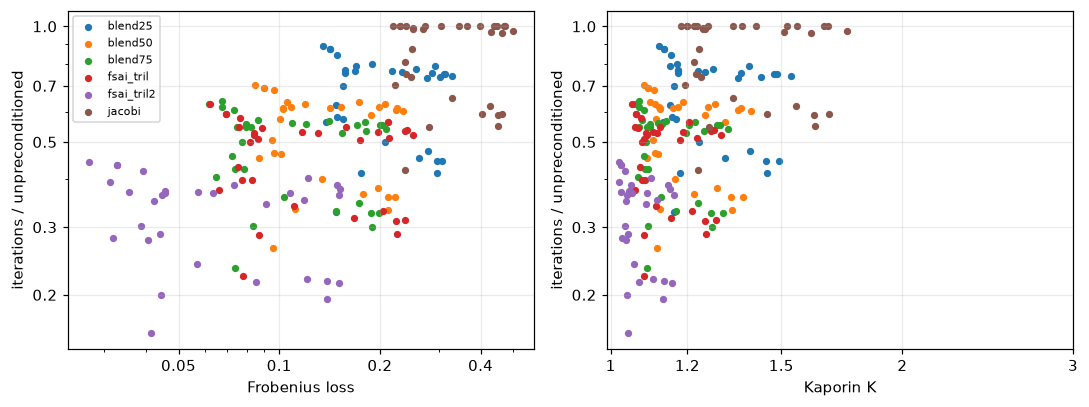

,pooled_R2,within_spearman_mean,within_spearman_min
loss,0.26695,0.916912,0.828571
kaporin,0.18562,0.998201,0.985611


In [9]:
from matplotlib.ticker import NullFormatter
d = pd.read_csv(R/'correlation_study.csv')
none = d[d.method=='none'].set_index('matrix').iters
d['rel_iters'] = d.apply(lambda r: r.iters/none[r.matrix], axis=1)
d = d[(d.method!='none')].dropna(subset=['loss','kaporin'])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, col, lab in zip(ax, ['loss', 'kaporin'], ['Frobenius loss', 'Kaporin K']):
    for m, g in d.groupby('method'): a.scatter(g[col], g.rel_iters, s=14, label=m)
    a.set_xscale('log'); a.set_yscale('log')
    a.xaxis.set_minor_formatter(NullFormatter()); a.yaxis.set_minor_formatter(NullFormatter())
    xt = [0.05, 0.1, 0.2, 0.4] if col == 'loss' else [1.0, 1.2, 1.5, 2.0, 3.0]
    a.set_xticks(xt); a.set_xticklabels([f'{v:g}' for v in xt])
    a.set_yticks([0.2, 0.3, 0.5, 0.7, 1.0]); a.set_yticklabels(['0.2', '0.3', '0.5', '0.7', '1.0'])
    a.set_xlabel(lab); a.set_ylabel('iterations / unpreconditioned')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
display(pd.read_csv(R/'correlation_summary.csv', index_col=0))

## 8. Spectra

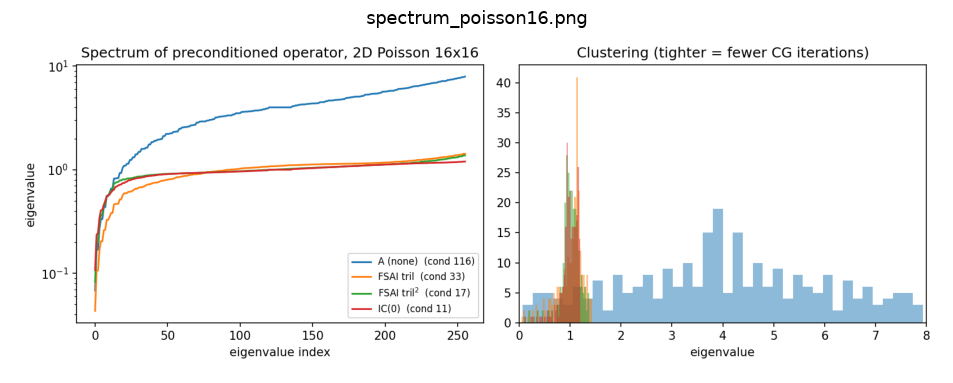

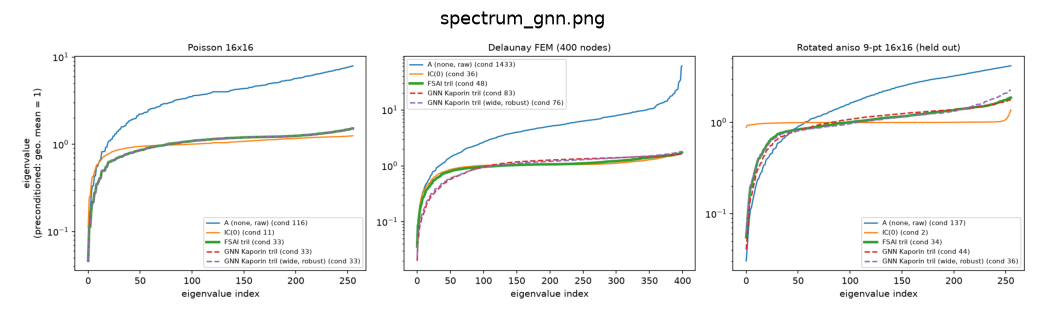

In [10]:
for name in ['spectrum_poisson16.png', 'spectrum_gnn.png']:
    p = R/name
    if p.exists():
        plt.figure(figsize=(12, 4)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(name); plt.show()
    else:
        print(name, 'not found')